<img src="img/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Applied Neural Networks: Projekt </b> <br> FS 2026 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

1. [Einleitung](01_Einleitung.ipynb)
2. [Datenerzeugung](02_Datenerzeugung.ipynb)
3. **ESN-Baseline auf sauberen Daten**
4. [Robustheit gegenüber Rauschen](04_Rauschen_Robustheit.ipynb)
5. [Out-of-Distribution-Analyse](05_Out_of_Distribution.ipynb)
6. [Schlussauswertung](06_Schluss.ipynb)

---

# 3. ESN-Baseline auf sauberen Daten

In diesem Notebook wird ein Echo State Network auf sauberen synthetischen Schwingungen trainiert und auf sauberen In-Distribution-Testdaten ausgewertet.

Dieses Notebook beantwortet die erste Teilfrage des Projekts:

***Wie gut funktioniert das ESN auf sauberen Testdaten innerhalb des Trainingsbereichs?***

Die Ergebnisse bilden die Referenz für die späteren Experimente mit Rauschen und Out-of-Distribution-Daten.

Der Ablauf ist:

1. Daten laden, prüfen und Evaluationsmetrik einführen
2. **Baseline** (3.5): Modell mit fixen Standardhyperparametern trainieren und evaluieren
3. **Optimiertes Modell** (3.6): Grid Search über Reservoir-Grösse und Spektralradius, dann finales Training und Evaluation
4. Ergebnisse speichern

## 3.1. Imports und Grundeinstellungen

Neben den Standardbibliotheken werden die projektspezifischen Hilfsmodule geladen:

- `esn_utils`: ESN-Modell, Datasets, Training und Evaluation
- `plot_utils`: Visualisierungsfunktionen für Trainingsverlauf und Evaluationsergebnisse

Für reproduzierbare Experimente werden NumPy und PyTorch mit festen Seeds initialisiert.

In [48]:
# Imports
import os
from typing import Any

import numpy as np
import pandas as pd

import torch

from IPython.display import clear_output
from joblib import Parallel, delayed

from utils import esn_utils as eu
from utils import plot_utils as pu

In [49]:
# Base Configuration
SEED = 67
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "data"
RESULTS_DIR = "results"
MODELS_DIR = "models"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print(f"Verwendetes Gerät: {DEVICE}")

Verwendetes Gerät: cpu


## 3.2. Daten laden und prüfen

Es werden nur die sauberen Trainingsdaten und die sauberen In-Distribution-Testdaten geladen:

```text
data/train_clean.npy
data/test_clean_id.npy
```

Jede Schwingung ist ein Dictionary mit `t`, `y` und `params`. Die Struktur wird direkt nach dem Laden geprüft.

OOD-Daten und verrauschte Daten werden hier bewusst nicht verwendet. Dieses Notebook erzeugt eine saubere Referenz-Baseline.

In [50]:
# Daten laden
train_clean = np.load(os.path.join(DATA_DIR, "train_clean.npy"), allow_pickle=True)
test_clean_id = np.load(os.path.join(DATA_DIR, "test_clean_id.npy"), allow_pickle=True)

print(f"Trainingsdaten: {len(train_clean)} Schwingungen")
print(f"Testdaten ID:   {len(test_clean_id)} Schwingungen")
print("Beispiel-Parameter Training:")
print(train_clean[0]["params"])

# Struktur prüfen
eu.validate_oscillation_dataset(train_clean, "train_clean")
eu.validate_oscillation_dataset(test_clean_id, "test_clean_id")

Trainingsdaten: 25 Schwingungen
Testdaten ID:   25 Schwingungen
Beispiel-Parameter Training:
{'A': np.float64(0.5273956048555963), 'alpha': 0.030480993855095773, 'omega': np.float64(3.366906371747029), 'phi': 4.381692553882582}
train_clean: Struktur OK, 25 Schwingungen
test_clean_id: Struktur OK, 25 Schwingungen


## 3.3. Datasets erstellen

Das ESN nutzt sein zeitliches Gedächtnis, indem das Reservoir sequenziell über vollständige Schwingungen läuft. Jedes Dataset-Sample ist deshalb eine ganze Zeitreihe.

Nach dem Durchlauf durch das Reservoir werden die gesammelten Reservoir-Zustände zu einem flachen `ReservoirStateDataset` zusammengefasst, auf dem `W_out` linear trainiert wird.

In [51]:
eu.set_seed(SEED)

train_sequence_dataset = eu.OscillationSequenceDataset(train_clean)
test_sequence_dataset = eu.OscillationSequenceDataset(test_clean_id)

print(f"Sequenzen Training: {len(train_sequence_dataset)}")
print(f"Sequenzen Test ID:  {len(test_sequence_dataset)}")

Sequenzen Training: 25
Sequenzen Test ID:  25


## 3.4. Evaluationsmetrik: NRMSE

Als Evaluationsmetrik wird der **NRMSE** (Normalized Root Mean Squared Error) verwendet:

$$
\text{NRMSE} = \frac{\text{RMSE}}{\max(y) - \min(y)}
= \frac{\displaystyle\sqrt{\frac{1}{T}\sum_{t=1}^{T}\bigl(y(t) - \hat{y}(t)\bigr)^2}}{\max(y) - \min(y)}
$$

**Warum NRMSE statt RMSE?**

Die Trainingsdaten enthalten gedämpfte Schwingungen mit Amplituden $A \in [0.5, 2.0]$. Ein absoluter RMSE von beispielsweise $0.01$ ist bei einer Schwingung mit $A = 0.5$ viel gravierender als bei einer mit $A = 2.0$. Durch die Normierung über den Wertebereich $\max(y) - \min(y)$ werden alle Schwingungen auf einer gemeinsamen Skala vergleichbar (unabhängig von Amplitude und Dämpfung).

## 3.5. Baseline

### 3.5.1. Konfiguration

Für die erste Baseline wird ein ESN mit 300 Reservoir-Neuronen und einem Spektralradius von 0.95 trainiert.

Diese Hyperparameter werden bewusst fix gehalten. Reservoir-Grösse und Spektralradius werden anschliessend in Abschnitt 3.6 gemeinsam via Grid Search systematisch optimiert.

In [52]:
# Baseline Hyperparameter
N_RESERVOIR = 300
SPECTRAL_RADIUS = 0.95
SPARSITY = 0.1
INPUT_SCALING = 1.0
LEAKING_RATE = 1.0
WARMUP = 100
N_EPOCHS = 100
LR = 1e-3
BATCH_SIZE = 256

baseline_config = {
    "n_reservoir": N_RESERVOIR,
    "spectral_radius": SPECTRAL_RADIUS,
    "sparsity": SPARSITY,
    "input_scaling": INPUT_SCALING,
    "leaking_rate": LEAKING_RATE,
    "warmup": WARMUP,
    "n_epochs": N_EPOCHS,
    "lr": LR,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
}

pd.DataFrame([baseline_config])

,n_reservoir,spectral_radius,sparsity,input_scaling,leaking_rate,warmup,n_epochs,lr,batch_size,seed
0,300,0.95,0.1,1.0,1.0,100,100,0.001,256,67


### 3.5.2. Modell und Reservoir-Zustände sammeln

Das Reservoir wird zufällig initialisiert und danach fixiert. Nur die Ausgabeschicht `W_out` bleibt trainierbar.

Anschliessend wird das Reservoir sequenziell über jede Schwingung laufen gelassen. Für jeden Zeitpunkt $t$ nach der Warmup-Phase werden Reservoir-Zustand $\mathbf{x}(t)$ und Zielwert $y(t+1)$ gespeichert. Diese Zustände bilden die Trainingsdaten für `W_out`.

Die ersten `warmup=100` Zeitschritte werden ignoriert, damit der künstliche Startzustand $\mathbf{x}(0) = 0$ keinen Einfluss auf die Trainingsdaten hat.

In [53]:
eu.set_seed(SEED)

baseline_model = eu.EchoStateNetwork(
    n_reservoir=N_RESERVOIR,
    spectral_radius=SPECTRAL_RADIUS,
    sparsity=SPARSITY,
    input_scaling=INPUT_SCALING,
    leaking_rate=LEAKING_RATE,
    seed=SEED,
    verbose=True,
).to(DEVICE)

X_train, y_train = eu.collect_states(
    baseline_model, train_sequence_dataset, warmup=WARMUP, device=DEVICE,
)
X_test, y_test = eu.collect_states(
    baseline_model, test_sequence_dataset, warmup=WARMUP, device=DEVICE,
)

print(f"X_train: {tuple(X_train.shape)}")
print(f"y_train: {tuple(y_train.shape)}")
print(f"X_test:  {tuple(X_test.shape)}")
print(f"y_test:  {tuple(y_test.shape)}")

ESN: N=300, trainierbar=301, fix=90300, spectral_radius=0.95, sparsity=0.1
X_train: (22475, 300)
y_train: (22475, 1)
X_test:  (22475, 300)
y_test:  (22475, 1)


### 3.5.3. Training

Trainiert wird nur `W_out`. Das Reservoir bleibt unverändert. Das entspricht einer linearen Regression im Reservoir-Zustandsraum.

Bei 25 Schwingungen mit 1000 Zeitschritten und `warmup=100` entstehen pro Datensatz $25 \times 899 = 22\,475$ Trainingspunkte.

Epoche   1/100 | Train-NRMSE=0.220621 | Test-NRMSE=0.015986
Epoche  10/100 | Train-NRMSE=0.007866 | Test-NRMSE=0.005367
Epoche  20/100 | Train-NRMSE=0.004669 | Test-NRMSE=0.004127
Epoche  30/100 | Train-NRMSE=0.003327 | Test-NRMSE=0.003563
Epoche  40/100 | Train-NRMSE=0.002739 | Test-NRMSE=0.003105
Epoche  50/100 | Train-NRMSE=0.002341 | Test-NRMSE=0.002546
Epoche  60/100 | Train-NRMSE=0.002001 | Test-NRMSE=0.002510
Epoche  70/100 | Train-NRMSE=0.001676 | Test-NRMSE=0.001878
Epoche  80/100 | Train-NRMSE=0.001396 | Test-NRMSE=0.001881
Epoche  90/100 | Train-NRMSE=0.001298 | Test-NRMSE=0.001475
Epoche 100/100 | Train-NRMSE=0.001183 | Test-NRMSE=0.001432


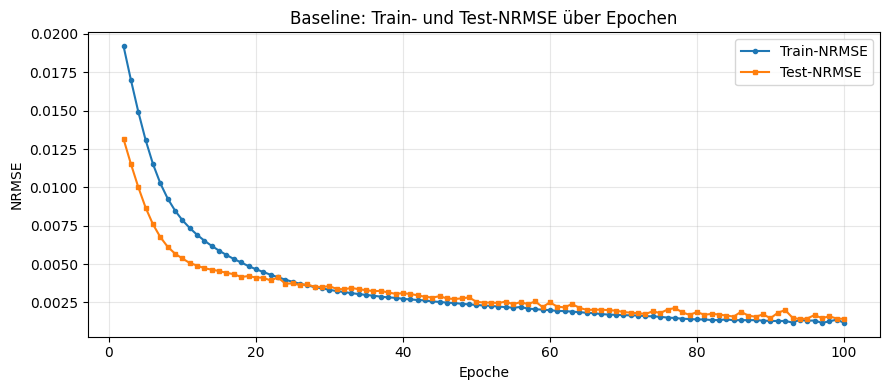

In [54]:
train_losses, test_losses = eu.train_readout(
    baseline_model,
    X_train, y_train, X_test, y_test,
    n_epochs=N_EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    device=DEVICE,
    print_every=10,
)

pu.plot_training_curves(
    train_losses, test_losses,
    title="Baseline: Train- und Test-NRMSE über Epochen",
    skip_first=True,
)

**Beobachtung:**  

Beide Kurven starten hoch und fallen in den ersten Epochen steil ab. Der Test-NRMSE startet dabei deutlich tiefer als der Train-NRMSE. Das liegt daran, dass `W_out` zu Beginn zufällig initialisiert ist und die Testsequenzen zufällig günstiger in den Ausgangszustand fallen als die Trainingssequenzen.

Ab etwa Epoche 30 überholt die Train-Kurve die Test-Kurve. Der Grund: `W_out` wird nur auf den Reservoir-Zuständen der Trainingssequenzen (`X_train`) optimiert. Da Trainings- und Testsequenzen unterschiedliche Parameter $(A, \alpha, \omega, \phi)$ haben, erzeugen sie unterschiedliche Zustände im Reservoir. Mit jeder Epoche passt sich `W_out` besser an die Trainingssequenzen an, während der Test-NRMSE stagniert. Dies ist kein klassisches Overfitting (301 Parameter auf 22 475 Punkten), sondern eine natürliche Spezialisierung auf die Trainingsdaten.

Der entscheidende Wert ist aber der sequenzielle NRMSE auf vollständigen Testschwingungen im nächsten Abschnitt.

### 3.5.4. Evaluation

Das trainierte Modell wird sequenziell auf allen 25 In-Distribution-Testschwingungen ausgewertet. Für jede Schwingung wird der NRMSE über die Zeitschritte nach der Warmup-Phase berechnet.

In [55]:
baseline_nrmse_df = eu.evaluate_model(
    baseline_model, test_clean_id, warmup=WARMUP, device=DEVICE,
)

baseline_nrmse_summary = {
    "mean_nrmse": baseline_nrmse_df["nrmse"].mean(),
    "std_nrmse": baseline_nrmse_df["nrmse"].std(),
    "min_nrmse": baseline_nrmse_df["nrmse"].min(),
    "max_nrmse": baseline_nrmse_df["nrmse"].max(),
}

pd.DataFrame([baseline_nrmse_summary])

,mean_nrmse,std_nrmse,min_nrmse,max_nrmse
0,0.001683,0.000885,0.000883,0.004346


**Beobachtung:**  
Ein NRMSE von 0.001683 entspricht 0.1683% des Signalbereichs (roher Quotient). Der NRMSE liegt deutlich unter 1 %, was zeigt, dass das ESN die Schwingungen bereits mit einfachen Standardhyperparametern sehr präzise vorhersagt.

### 3.5.5. Beispielvorhersagen

Zur qualitativen Kontrolle werden sechs Testschwingungen geplottet — jeweils die echte Schwingung und die sequenzielle One-Step-Ahead-Vorhersage des ESN.

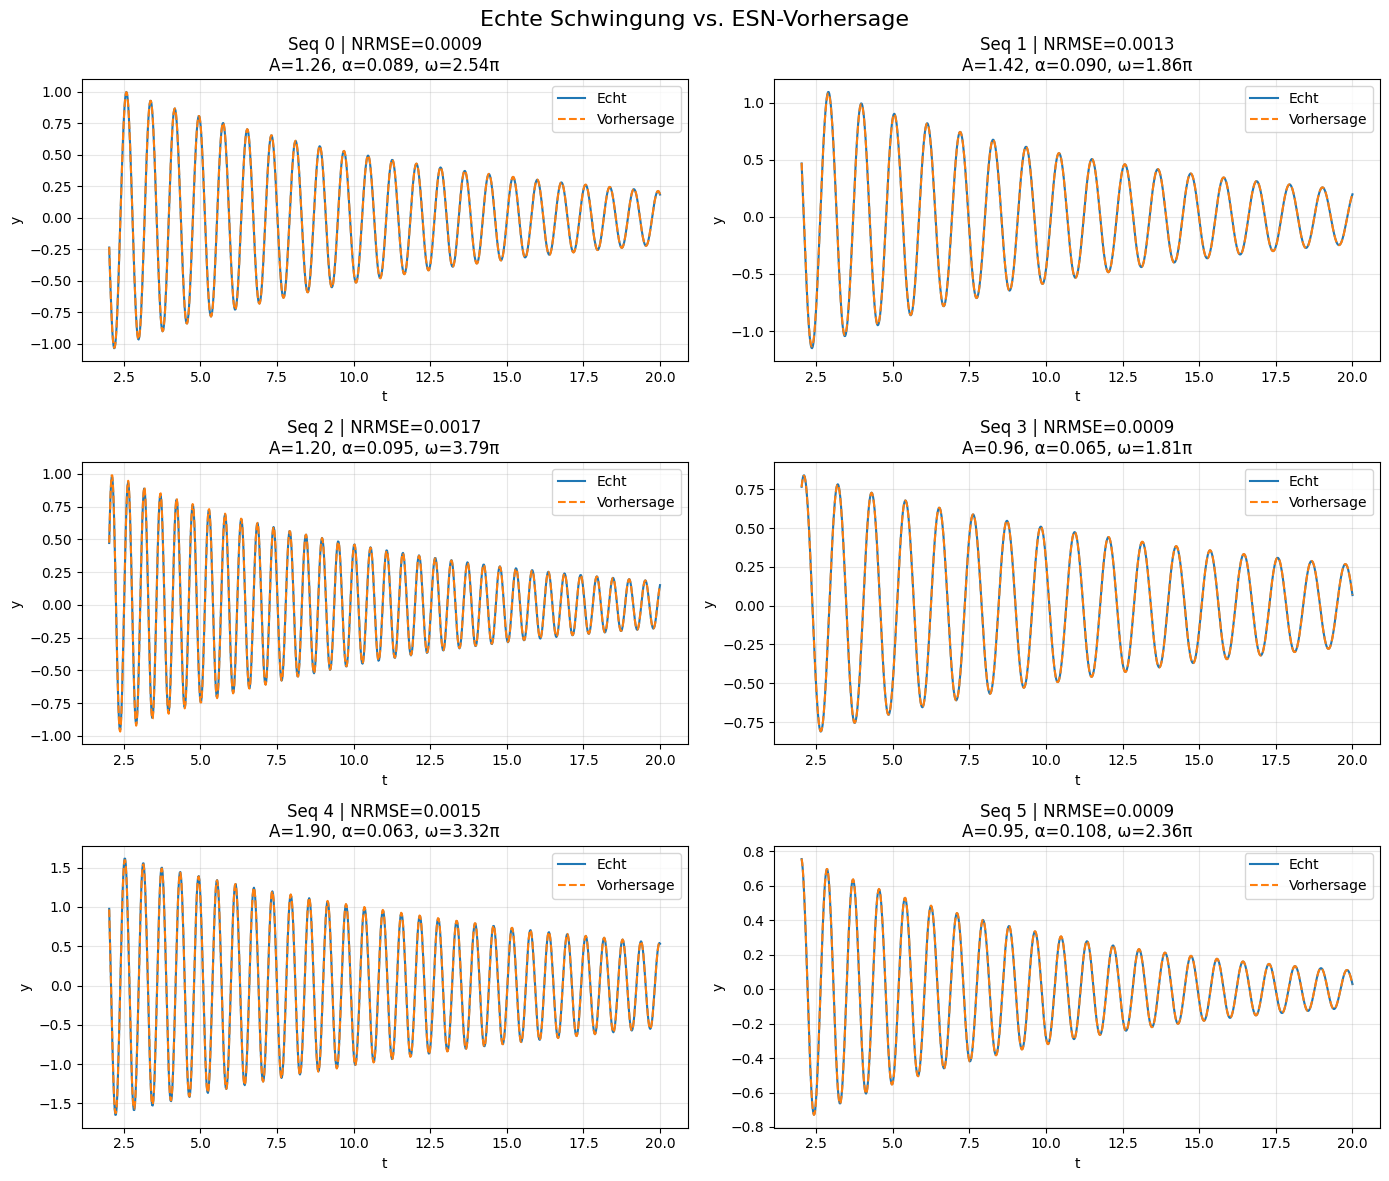

In [56]:
pu.plot_sequence_predictions(
    baseline_model, test_clean_id, baseline_nrmse_df,
    n_examples=6, warmup=WARMUP, device=DEVICE,
)

**Beobachtung:**

Das sieht schon mal sehr sauber aus. Um es spannend zu machen, werden trotzdem noch Hyperparameter optimiert.

### 3.5.6. NRMSE-Verteilung und Fehleranalyse

Das Balkendiagramm zeigt den NRMSE pro Sequenz. Damit werden Ausreisser sichtbar. Das Histogramm gibt einen Überblick über die gesamte Fehlerverteilung. Der Fehlerplot über Zeit zeigt, bei welchen Sequenzen und in welchen Zeitbereichen das Modell am stärksten abweicht.

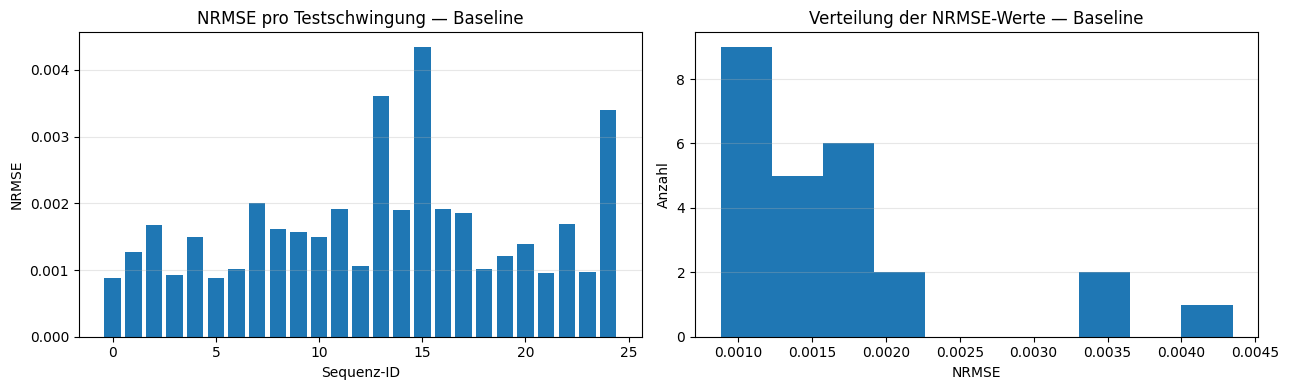

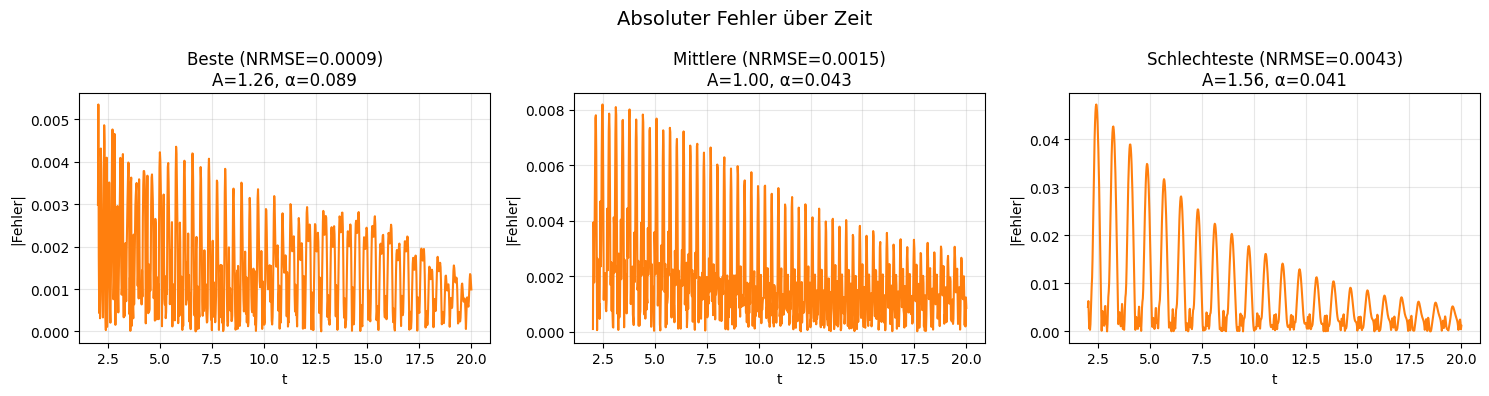

Mittlerer NRMSE:     0.001683
Standardabweichung:  0.000885
Bester NRMSE:        0.000883
Schlechtester NRMSE: 0.004346


In [57]:
pu.plot_nrmse_distribution(baseline_nrmse_df, title_suffix=" — Baseline")

pu.plot_error_over_time(
    baseline_model, test_clean_id, baseline_nrmse_df,
    warmup=WARMUP, device=DEVICE,
)

print(f"Mittlerer NRMSE:     {baseline_nrmse_df['nrmse'].mean():.6f}")
print(f"Standardabweichung:  {baseline_nrmse_df['nrmse'].std():.6f}")
print(f"Bester NRMSE:        {baseline_nrmse_df['nrmse'].min():.6f}")
print(f"Schlechtester NRMSE: {baseline_nrmse_df['nrmse'].max():.6f}")

Auffallend sind die Sequenzen mit den IDs `13, 15, 24`.

### 3.5.7. NRMSE vs. Schwingungsparameter

Die Parameter jeder Testschwingung ($A$, $\alpha$, $\omega$) sind in den geladenen `.npy`-Dateien gespeichert und werden direkt aus der Evaluation ausgelesen.

Die Streudiagramme zeigen, ob bestimmte Parameterregionen systematisch schwieriger vorherzusagen sind — etwa stark gedämpfte Schwingungen oder solche mit hoher Frequenz.

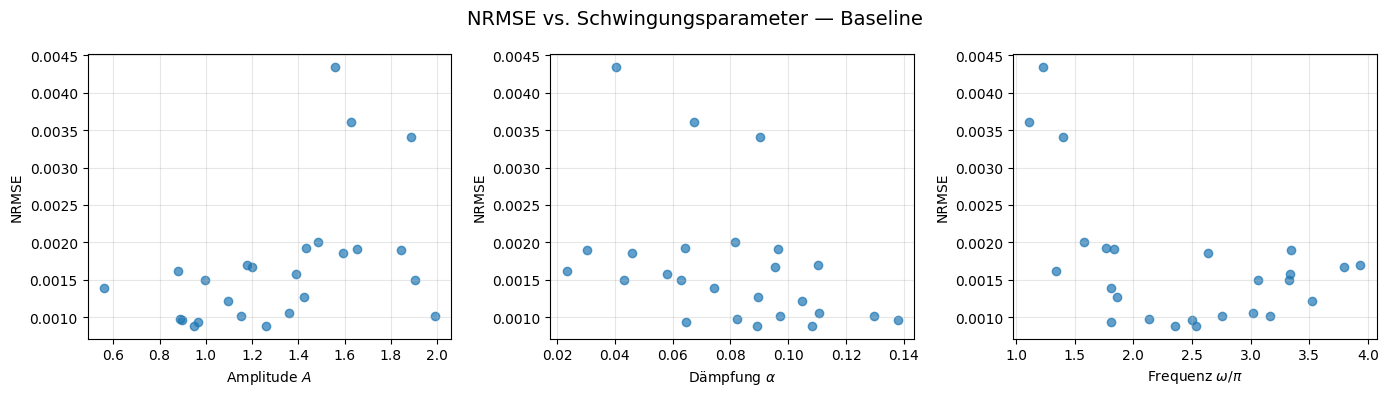

In [58]:
pu.plot_nrmse_vs_params(baseline_nrmse_df, title_suffix="— Baseline")

Es scheint, dass die drei Schwingungen (`13, 15, 24`) auffallen, weil sie eine hohe Frequenz und eine hohe Amplitude haben. Das liegt vermutlich daran, dass die Schwingdynamik besonders schnell ist und das Reservoir mit dem gewählten Spektralradius zu träge reagiert, um die Einhüllende korrekt zu verfolgen.

## 3.6. Optimiertes Modell

### 3.6.1. Grid Search: Reservoir-Grösse und Spektralradius

Um die wichtigsten Hyperparameter systematisch zu optimieren, wird eine Grid Search über Reservoir-Grösse $N$ und Spektralradius $\rho$ durchgeführt.

| Hyperparameter | Getestete Werte |
|---|---|
| Reservoir-Grösse $N$ | 100, 150, 200, 250, 300, 350, 400, 450, 500, 550 |
| Spektralradius $\rho$ | 0.70, 0.80, 0.90, 0.95, 0.96, 0.97, 0.98, 0.99, 1.00, 1.05 |
| Seeds pro Kombination | 10 |

Für jede Kombination wird das ESN mit 10 verschiedenen Seeds trainiert. Der mittlere NRMSE über die Seeds bestimmt die beste Konfiguration. Die Seed-Varianz quantifiziert zusätzlich die Stabilität.

**Parallelisierung:** Die Grid Search umfasst $10 \times 10 \times 10 = 1\,000$ Trainingsläufe. Da jeder Lauf vollständig unabhängig von allen anderen ist (kein gemeinsamer Zustand, kein geteiltes Reservoir), können mehrere Läufe gleichzeitig auf verschiedenen CPU-Kernen ausgeführt werden. Dafür wird `joblib.Parallel` mit dem `loky`-Backend verwendet, das bis zu `N_JOBS = min(6, CPU-Kerne - 1)` Prozesse parallel startet. Im Vergleich zur sequenziellen Ausführung reduziert sich die Laufzeit dadurch um einen Faktor von bis zu 6.

In [59]:
reservoir_sizes = [100, 150, 200, 250, 300, 350, 400, 450, 500, 550]
spectral_radii = [0.7, 0.8, 0.9, 0.95, 0.96, 0.97, 0.98, 0.99, 1.0, 1.05]
n_seeds = 10

SEARCH_DEVICE = torch.device("cpu")
SEARCH_EPOCHS = N_EPOCHS
N_JOBS = min(6, max(1, os.cpu_count() - 1))

grid_tasks = [
    (N, sr, i)
    for N in reservoir_sizes
    for sr in spectral_radii
    for i in range(n_seeds)
]
total_runs = len(grid_tasks)

print(f"Reservoir-Grössen:    {reservoir_sizes}")
print(f"Spektralradien:       {spectral_radii}")
print(f"Seeds pro Kombi:      {n_seeds}")
print(f"Parallele Jobs:       {N_JOBS}")
print(f"Anzahl Trainingsläufe: {total_runs}")


def run_single_grid_search(n_reservoir: int, spectral_radius: float, seed_offset: int) -> dict[str, Any]:
    torch.set_num_threads(1)
    seed = SEED + seed_offset

    run = eu.train_and_evaluate_esn(
        n_reservoir=n_reservoir,
        train_dataset=train_sequence_dataset,
        test_dataset=test_sequence_dataset,
        test_data_raw=test_clean_id,
        spectral_radius=spectral_radius,
        sparsity=SPARSITY,
        input_scaling=INPUT_SCALING,
        leaking_rate=LEAKING_RATE,
        warmup=WARMUP,
        n_epochs=SEARCH_EPOCHS,
        lr=LR,
        batch_size=BATCH_SIZE,
        seed=seed,
        device=SEARCH_DEVICE,
        verbose=False,
        print_every=0,
    )
    return {
        "n_reservoir": n_reservoir,
        "spectral_radius": spectral_radius,
        "seed": seed,
        "mean_nrmse": run["mean_nrmse"],
    }


grid_rows = []

parallel_results = Parallel(
    n_jobs=N_JOBS, backend="loky", verbose=0, return_as="generator_unordered",
)(
    delayed(run_single_grid_search)(N, sr, i)
    for N, sr, i in grid_tasks
)

for completed, row in enumerate(parallel_results, start=1):
    grid_rows.append(row)
    percent = completed / total_runs * 100
    clear_output(wait=True)
    print(f"Grid Search läuft: {completed}/{total_runs} ({percent:.1f}%)")
    print(f"Letzter Lauf: N={row['n_reservoir']}, SR={row['spectral_radius']:.2f}, NRMSE={row['mean_nrmse']:.6f}")

grid_all = pd.DataFrame(grid_rows)

grid_summary = (
    grid_all
    .groupby(["n_reservoir", "spectral_radius"])
    .agg(
        mean_nrmse=("mean_nrmse", "mean"),
        std_nrmse=("mean_nrmse", "std"),
        median_nrmse=("mean_nrmse", "median"),
    )
    .reset_index()
)
grid_summary["rel_std_nrmse"] = grid_summary["std_nrmse"] / grid_summary["median_nrmse"] * 100

best_grid_idx = grid_summary["mean_nrmse"].idxmin()
best_grid_row = grid_summary.loc[best_grid_idx]
best_n_reservoir = int(best_grid_row["n_reservoir"])
best_sr = float(best_grid_row["spectral_radius"])

best_configs = grid_summary[
    grid_summary["mean_nrmse"] <= grid_summary["mean_nrmse"].min() + 1e-8
][["n_reservoir", "spectral_radius"]].values

clear_output(wait=True)
print("Grid Search abgeschlossen")
print(f"Beste Reservoir-Grösse: N={best_n_reservoir}")
print(f"Bester Spektralradius:  SR={best_sr}")
print(f"Mittlerer NRMSE:        {best_grid_row['mean_nrmse']:.6f}")

Grid Search abgeschlossen
Beste Reservoir-Grösse: N=400
Bester Spektralradius:  SR=0.98
Mittlerer NRMSE:        0.001647


Die Heatmap zeigt den mittleren NRMSE (über 10 Seeds) für jede Kombination aus Reservoir-Grösse und Spektralradius. Die beste Kombination ist grün markiert.

Der 3D-Plot zeigt dieselben Ergebnisse. Die orangen Flächen entsprechen dem ±1-Std-Band und können über die Legende ein- und ausgeblendet werden.

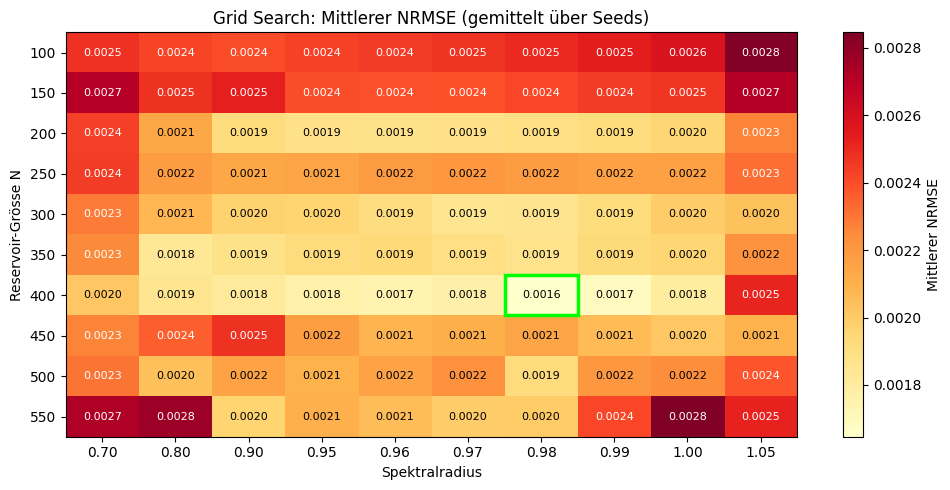

In [60]:
heatmap_data = pu.plot_grid_search_heatmap(grid_summary, best_configs)

In [61]:
pu.plot_grid_search_3d(grid_summary, heatmap_data, best_configs)

**Beobachtung:**
- Es ist zu bemerken, dass die beiden Reihen mit 200 und 250 Neuronen herausstechen, weil sie das Muster brechen. Die Reihe mit 200 würde vom Muster her nach 250 oder sogar nach 300 hineinpassen.
- Nach 400 Neuronen werden die Ergebnisse wieder schlechter, jedoch ist unklar ob es bei viel mehr Neuronen wieder besser wird, vermutlich nicht.
- Es sieht fast so aus, als ob es eine Wellenform gibt.

Der **Spektralradius** $\rho$ ist der grösste Absolutwert unter den Eigenwerten der Reservoir-Gewichtsmatrix. Er bestimmt, wie lange das Reservoir vergangene Eingaben "erinnert": Ein tiefer Wert ($\rho \ll 1$) lässt die Zustände schnell abklingen, das Reservoir vergisst schnell. Ein Wert nahe 1 führt zu einem langen Gedächtnis. Das heisst vergangene Eingaben wirken noch viele Zeitschritte nach.

Für die gedämpften Schwingungen in diesem Projekt ist ein langes Gedächtnis vorteilhaft, da die relevante Dynamik sich über viele Zeitschritte erstreckt. Das erklärt, warum $\rho = 0.98$ optimal ist.

Werte $\rho \geq 1$ wurden trotzdem getestet, weil die theoretische Stabilitätsbedingung ($\rho < 1$, die sogenannte *Echo State Property*) nur für den Fall ohne Eingabe gilt.

Vermutung: Sobald das Reservoir kontinuierlich durch ein Eingabesignal angetrieben wird, können auch Werte bei oder leicht über 1 stabil bleiben. In der Praxis ist die Grenze fliessend.

Die Ergebnisse zeigen jedoch, dass $\rho = 1.00$ und $\rho = 1.05$ schlechter abschneiden. Das Reservoir wird zu instabil.

Die relative Standardabweichung zeigt, wie stark die NRMSE-Werte über die 10 Seeds streuen (relativ zum Median). Hohe relative Streuung bedeutet seed-abhängige, instabile Ergebnisse, auch wenn der mittlere NRMSE gut aussieht.

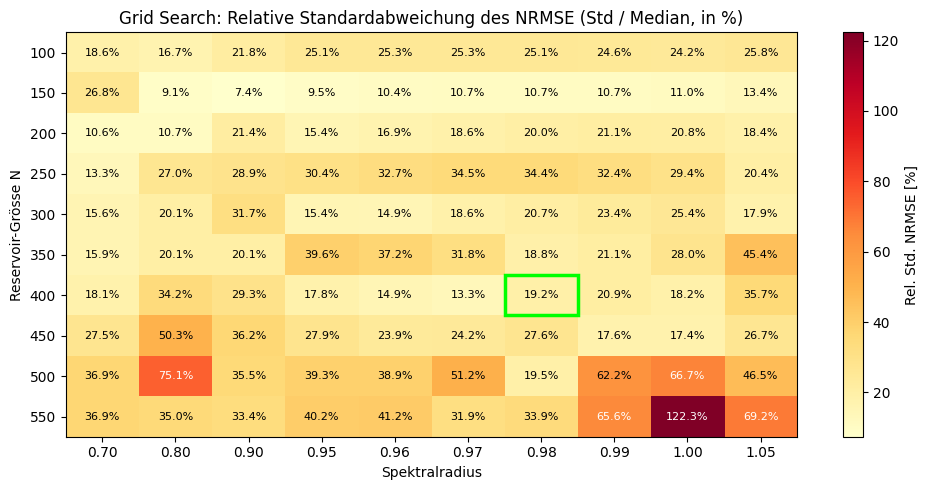

In [62]:
rel_std_pivot = pu.plot_grid_search_rel_std_heatmap(grid_summary, best_configs)
pu.plot_grid_search_rel_std_3d(rel_std_pivot, best_configs)

**Beobachtung:**
- Die Ergebnisse sind nicht überraschend.
- Das beste Modell scheint auch stabile Vorhersagen zu treffen.

### 3.6.2. Training

Das beste Hyperparameter-Paar aus der Grid Search wird mit `n_seeds` verschiedenen Seeds trainiert. Als Referenzmodell wird der Lauf mit `seed=SEED` verwendet.

In [63]:
print(f"Trainiere finales Modell: N={best_n_reservoir}, SR={best_sr:.2f}, {n_seeds} Seeds")

all_train_losses = []
all_test_losses = []

for i in range(n_seeds):
    seed = SEED + i
    run = eu.train_and_evaluate_esn(
        n_reservoir=best_n_reservoir,
        train_dataset=train_sequence_dataset,
        test_dataset=test_sequence_dataset,
        test_data_raw=test_clean_id,
        spectral_radius=best_sr,
        sparsity=SPARSITY,
        input_scaling=INPUT_SCALING,
        leaking_rate=LEAKING_RATE,
        warmup=WARMUP,
        n_epochs=SEARCH_EPOCHS,
        lr=LR,
        batch_size=BATCH_SIZE,
        seed=seed,
        device=DEVICE,
        verbose=False,
        print_every=0,
    )
    all_train_losses.append(run["train_losses"])
    all_test_losses.append(run["test_losses"])
    if seed == SEED:
        best_run = run
        best_model = run["model"]

train_losses_mean = np.mean(all_train_losses, axis=0).tolist()
test_losses_mean = np.mean(all_test_losses, axis=0).tolist()
train_losses_std = np.std(all_train_losses, axis=0).tolist()
test_losses_std = np.std(all_test_losses, axis=0).tolist()

print("Training abgeschlossen.")
print(f"Mean NRMSE (seed={SEED}): {best_run['mean_nrmse']:.6f}")

Trainiere finales Modell: N=400, SR=0.98, 10 Seeds
Training abgeschlossen.
Mean NRMSE (seed=67): 0.001578


### 3.6.3. Trainingskurven

Die Trainingskurven sind über alle `n_seeds` gemittelt. Das Standardabweichungsband zeigt die Stabilität über verschiedene Zufallsinitialisierungen.

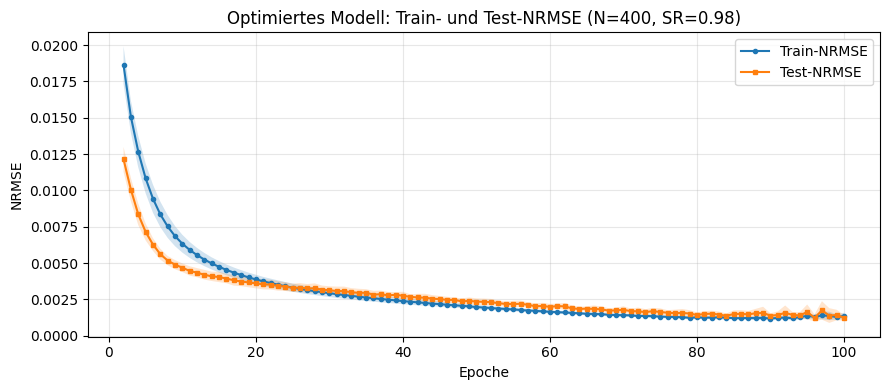

In [64]:
pu.plot_training_curves(
    train_losses_mean, test_losses_mean,
    title=f"Optimiertes Modell: Train- und Test-NRMSE (N={best_n_reservoir}, SR={best_sr:.2f})",
    skip_first=True,
    train_stds=train_losses_std,
    test_stds=test_losses_std,
)

**Beobachtung:**

Das Verhalten ist dasselbe wie bei der Baseline: Beide Kurven fallen zu Beginn steil ab, der Test-NRMSE startet tiefer, und die Train-Kurve überholt den Test. Der Unterschied ist, dass das optimierte Modell (N=400, SR=0.98) dieses Muster in weniger Epochen durchläuft. Die Konvergenz ist schneller. Das grössere Reservoir liefert reichhaltigere Zustände, wodurch `W_out` die relevanten Muster früher erlernt. Das Standardabweichungsband über die 10 Seeds zeigt, dass dieses Verhalten stabil und reproduzierbar ist.

### 3.6.4. Evaluation

Das beste Modell (seed=SEED) wird sequenziell auf allen In-Distribution-Testschwingungen ausgewertet. Diese Werte sind die finale Baseline dieses Notebooks.

In [65]:
best_nrmse_df = eu.evaluate_model(
    best_model, test_clean_id, warmup=WARMUP, device=DEVICE,
)

best_summary = {
    "best_n_reservoir": best_n_reservoir,
    "best_spectral_radius": best_sr,
    "final_seed": SEED,
    "mean_nrmse_id": best_nrmse_df["nrmse"].mean(),
    "std_nrmse_id": best_nrmse_df["nrmse"].std(),
    "min_nrmse_id": best_nrmse_df["nrmse"].min(),
    "max_nrmse_id": best_nrmse_df["nrmse"].max(),
    "sparsity": SPARSITY,
    "input_scaling": INPUT_SCALING,
    "leaking_rate": LEAKING_RATE,
    "warmup": WARMUP,
    "n_epochs": SEARCH_EPOCHS,
    "lr": LR,
    "batch_size": BATCH_SIZE,
}

baseline_summary = pd.DataFrame([best_summary])
baseline_summary

,best_n_reservoir,best_spectral_radius,final_seed,mean_nrmse_id,std_nrmse_id,min_nrmse_id,max_nrmse_id,sparsity,input_scaling,leaking_rate,warmup,n_epochs,lr,batch_size
0,400,0.98,67,0.001578,0.000635,0.000925,0.00351,0.1,1.0,1.0,100,100,0.001,256


### 3.6.5. Beispielvorhersagen

Zur qualitativen Kontrolle werden sechs Testschwingungen mit dem optimierten Modell dargestellt.

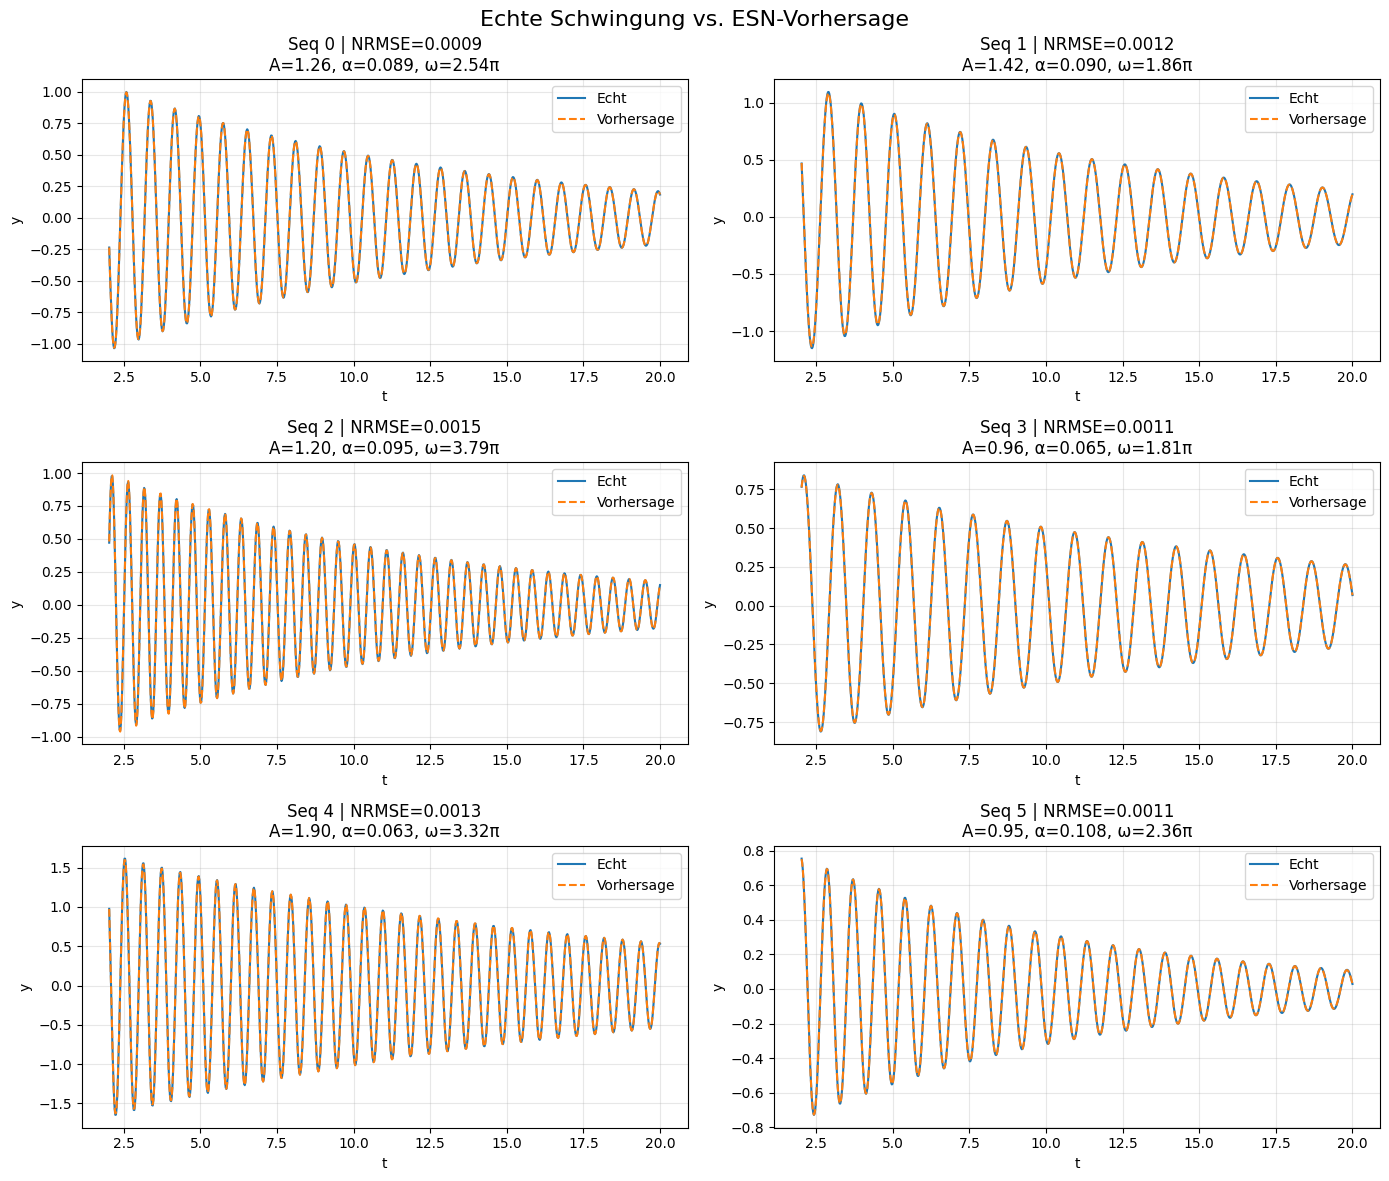

In [66]:
pu.plot_sequence_predictions(
    best_model, test_clean_id, best_nrmse_df,
    n_examples=6, warmup=WARMUP, device=DEVICE,
)

### 3.6.6. NRMSE-Verteilung und Fehleranalyse

Dieselben Diagnoseplots wie für die Baseline, jetzt für das optimierte Modell.

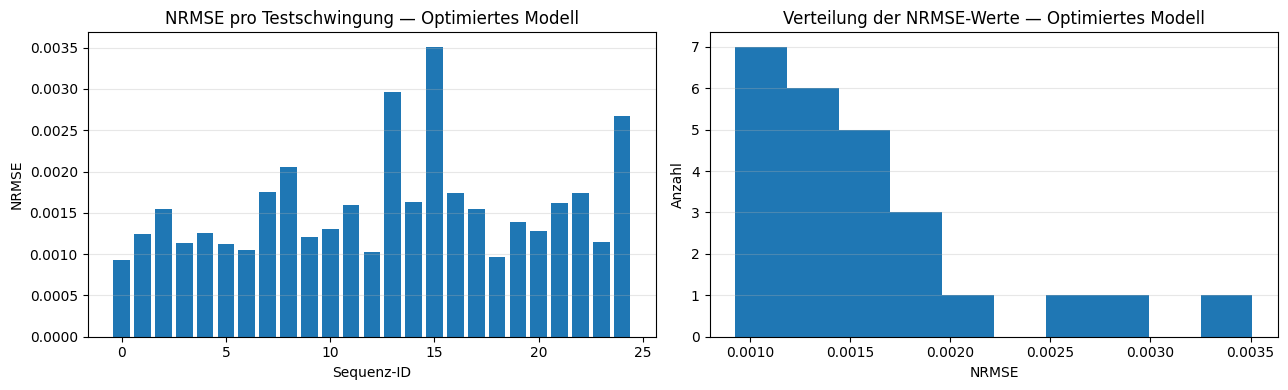

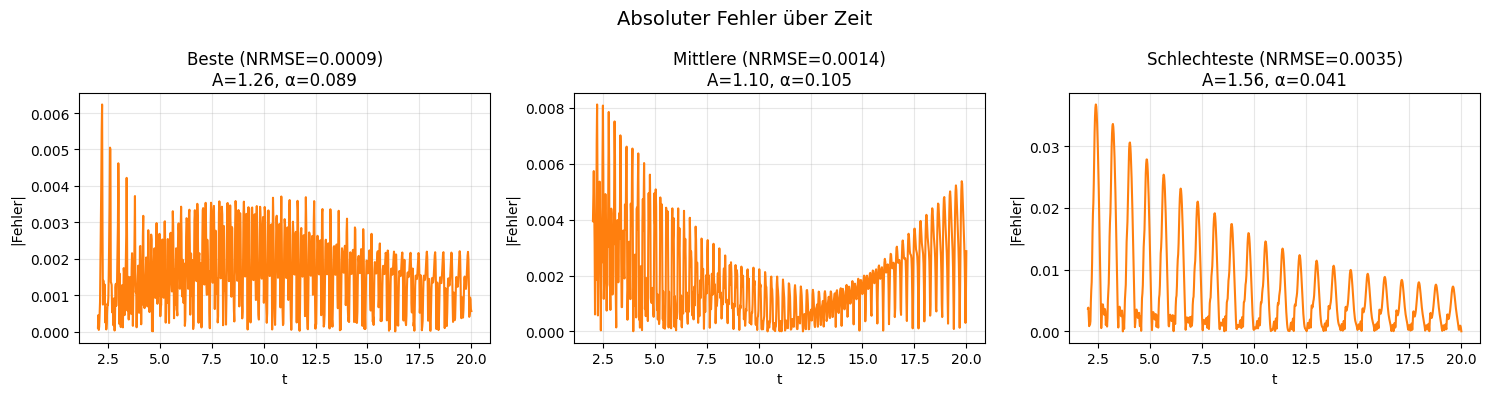

Mittlerer NRMSE:     0.001578
Standardabweichung:  0.000635
Bester NRMSE:        0.000925
Schlechtester NRMSE: 0.003510


In [67]:
pu.plot_nrmse_distribution(best_nrmse_df, title_suffix=" — Optimiertes Modell")

pu.plot_error_over_time(
    best_model, test_clean_id, best_nrmse_df,
    warmup=WARMUP, device=DEVICE,
)

print(f"Mittlerer NRMSE:     {best_nrmse_df['nrmse'].mean():.6f}")
print(f"Standardabweichung:  {best_nrmse_df['nrmse'].std():.6f}")
print(f"Bester NRMSE:        {best_nrmse_df['nrmse'].min():.6f}")
print(f"Schlechtester NRMSE: {best_nrmse_df['nrmse'].max():.6f}")

Es sind wieder die gleichen Schwingungen, die herausstechen. Dies unterstützt die Argumentation, dass es an der schnellen Dynamik liegt, also dass das Modell für diese drei Sequenzen zu träge ist.

Zum Vergleich sind hier die Werte der Baseline:

```text
Mittlerer NRMSE:        0.001683
Standardabweichung:     0.000885
Bester NRMSE:           0.000883
Schlechtester NRMSE:    0.004346
```

Die Ergebnisse sind besser geworden, jedoch ist der beste NRMSE ein bisschen schlechter.

### 3.6.7. NRMSE vs. Schwingungsparameter

Analog zur Baseline-Analyse: Zeigen Amplitude, Dämpfung oder Frequenz einen systematischen Zusammenhang mit dem Vorhersagefehler?

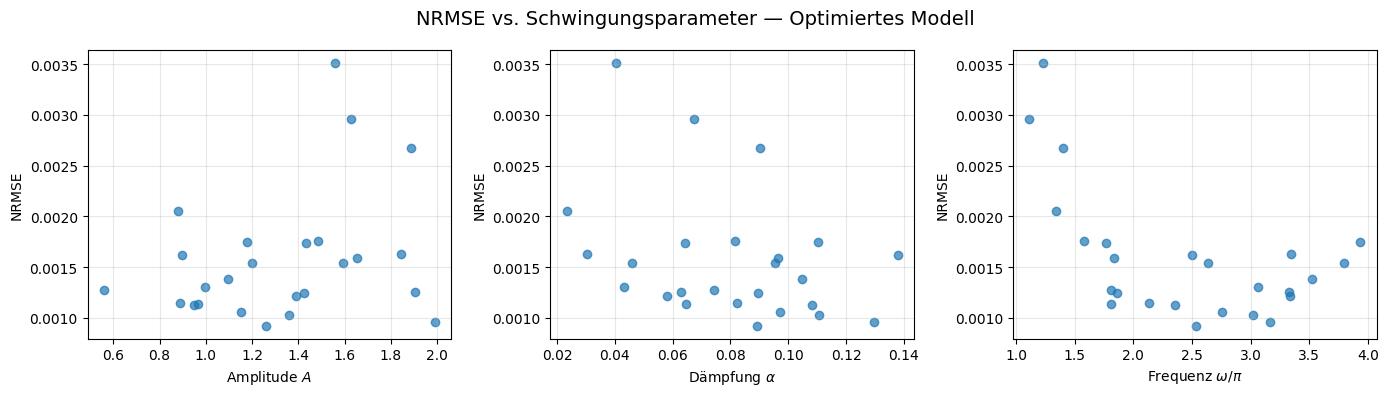

In [68]:
pu.plot_nrmse_vs_params(best_nrmse_df, title_suffix="— Optimiertes Modell")

## 3.7. Ergebnisse speichern

Die wichtigsten Resultate werden gespeichert, damit die folgenden Notebooks direkt darauf zugreifen können:

```text
results/baseline_summary.csv
results/baseline_grid_search.csv
results/baseline_sequence_nrmse.csv
models/esn_baseline_best.pt
```

In [69]:
baseline_summary.to_csv(os.path.join(RESULTS_DIR, "baseline_summary.csv"), index=False)
grid_summary.to_csv(os.path.join(RESULTS_DIR, "baseline_grid_search.csv"), index=False)
best_nrmse_df.to_csv(os.path.join(RESULTS_DIR, "baseline_sequence_nrmse.csv"), index=False)

checkpoint = {
    "model_state_dict": best_model.state_dict(),
    "config": best_summary,
}
torch.save(checkpoint, os.path.join(MODELS_DIR, "esn_baseline_best.pt"))

print("Gespeicherte Dateien:")
for path in [
    os.path.join(RESULTS_DIR, "baseline_summary.csv"),
    os.path.join(RESULTS_DIR, "baseline_grid_search.csv"),
    os.path.join(RESULTS_DIR, "baseline_sequence_nrmse.csv"),
    os.path.join(MODELS_DIR, "esn_baseline_best.pt"),
]:
    print(f"  {path}")

Gespeicherte Dateien:
  results/baseline_summary.csv
  results/baseline_grid_search.csv
  results/baseline_sequence_nrmse.csv
  models/esn_baseline_best.pt


## 3.8. Validierung

Die Projektanleitung fordert eine *kreuzvalidierte Performance*. Für dieses Projekt wird begründet, weshalb ein separater Holdout-Testdatensatz dem klassischen K-Fold-CV vorzuziehen ist:

**Klassische K-Fold-Kreuzvalidierung** (über einzelne Zeitschritte) ist für Zeitreihendaten grundsätzlich problematisch: Sie bricht die zeitliche Reihenfolge auf und würde den künstlichen Anfangszustand $\mathbf{x}(0) = 0$ des Reservoirs mitten in Trainingssequenzen einstreuen, was zu einer systematischen Verfälschung der Reservoir-Zustände führt.

**Stattdessen** wird die Performance auf einem **separaten Holdout-Testdatensatz** mit 25 unabhängig generierten Sequenzen bewertet. Dieser Datensatz wird einmalig zu Beginn erzeugt und während der gesamten Hyperparameter-Optimierung nicht verwendet. Da die Ausgabeschicht $W_{\text{out}}$ eine lineare Abbildung mit 301 Parametern auf circa 22 000 Trainingspunkten ist, ist Overfitting vernachlässigbar — CV würde hier keine zusätzliche Information liefern.

Die Stabilität der Ergebnisse wird zusätzlich durch **10 verschiedene Seeds** in der Grid Search quantifiziert (NRMSE-Mittelwert und Standardabweichung über Seeds). Diese Kombination aus separatem Holdout und Seed-Varianz ist für ESN-Zeitreihenprojekte die methodisch korrektere Validierungsstrategie [Lukoševičius, 2012].

## 3.9. Fazit

Das ESN funktioniert auf sauberen In-Distribution-Daten sehr gut. Die Teilfrage *Wie gut funktioniert das ESN auf sauberen Testdaten innerhalb des Trainingsbereichs?* kann klar beantwortet werden: sehr gut.

| Modell | Mittlerer NRMSE | Std |
|---|---|---|
| Baseline (N=300, SR=0.95) | 0.001683 | 0.000885 |
| Optimiert (N=400, SR=0.98) | 0.001578 | 0.000635 |

Ein NRMSE unter 0.2 % des Signalbereichs bedeutet, dass das ESN die Schwingungsdynamik nahezu perfekt erlernt, obwohl nur die lineare Ausgabeschicht `W_out` (301 Parameter) trainiert wurde.

Die Grid Search zeigt, dass ein hoher Spektralradius ($\rho = 0.98$) optimal ist: Das Reservoir benötigt ein langes Gedächtnis, um die langsam abklingenden Schwingungsdynamiken zu erfassen. Ein Reservoir mit 400 Neuronen bietet genug Kapazität, ohne zu überparametrisieren.

Konsistent auffällig sind die Sequenzen 13, 15 und 24. Beide Modelle zeigen dort die höchsten Fehler. Die Parameter-Analyse deutet auf hohe Frequenz und hohe Amplitude hin, was die Schwingungsdynamik besonders schnell macht und das Reservoir überfordert.

Die gespeicherten Resultate dienen als Referenz für die folgenden Notebooks:

```text
results/baseline_summary.csv
models/esn_baseline_best.pt
```

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="02_Datenerzeugung.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="04_Rauschen_Robustheit.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>